In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

In [2]:
data = {
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rain', 'Rain',
                'Rain', 'Overcast', 'Sunny', 'Sunny', 'Rain',
                'Sunny', 'Overcast', 'Overcast', 'Rain'],

    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool',
                    'Cool', 'Cool', 'Mild', 'Cool', 'Mild',
                    'Mild', 'Mild', 'Hot', 'Mild'],

    'Humidity': ['High', 'High', 'High', 'High', 'Normal',
                 'Normal', 'Normal', 'High', 'Normal', 'Normal',
                 'Normal', 'High', 'Normal', 'High'],

    'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak',
             'Strong', 'Strong', 'Weak', 'Weak', 'Weak',
             'Strong', 'Strong', 'Weak', 'Strong'],

    'PlayTennis': ['No', 'No', 'Yes', 'Yes', 'Yes',
                   'No', 'Yes', 'No', 'Yes', 'Yes',
                   'Yes', 'Yes', 'Yes', 'No']
}

df = pd.DataFrame(data)

print(df)

     Outlook Temperature Humidity    Wind PlayTennis
0      Sunny         Hot     High    Weak         No
1      Sunny         Hot     High  Strong         No
2   Overcast         Hot     High    Weak        Yes
3       Rain        Mild     High    Weak        Yes
4       Rain        Cool   Normal    Weak        Yes
5       Rain        Cool   Normal  Strong         No
6   Overcast        Cool   Normal  Strong        Yes
7      Sunny        Mild     High    Weak         No
8      Sunny        Cool   Normal    Weak        Yes
9       Rain        Mild   Normal    Weak        Yes
10     Sunny        Mild   Normal  Strong        Yes
11  Overcast        Mild     High  Strong        Yes
12  Overcast         Hot   Normal    Weak        Yes
13      Rain        Mild     High  Strong         No


In [3]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()

encoders = {}

for column in df_encoded.columns:
    le = LabelEncoder()
    df_encoded[column] = le.fit_transform(df_encoded[column])
    encoders[column] = le

print(df_encoded)

    Outlook  Temperature  Humidity  Wind  PlayTennis
0         2            1         0     1           0
1         2            1         0     0           0
2         0            1         0     1           1
3         1            2         0     1           1
4         1            0         1     1           1
5         1            0         1     0           0
6         0            0         1     0           1
7         2            2         0     1           0
8         2            0         1     1           1
9         1            2         1     1           1
10        2            2         1     0           1
11        0            2         0     0           1
12        0            1         1     1           1
13        1            2         0     0           0


In [4]:
X = df_encoded.drop('PlayTennis', axis=1)
y = df_encoded['PlayTennis']

print("Independent Variables:")
print(X)

print("\nTarget Variable:")
print(y)

Independent Variables:
    Outlook  Temperature  Humidity  Wind
0         2            1         0     1
1         2            1         0     0
2         0            1         0     1
3         1            2         0     1
4         1            0         1     1
5         1            0         1     0
6         0            0         1     0
7         2            2         0     1
8         2            0         1     1
9         1            2         1     1
10        2            2         1     0
11        0            2         0     0
12        0            1         1     1
13        1            2         0     0

Target Variable:
0     0
1     0
2     1
3     1
4     1
5     0
6     1
7     0
8     1
9     1
10    1
11    1
12    1
13    0
Name: PlayTennis, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

In [ ]:
model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

model.fit(X_train, y_train)

print("ID3 Decision Tree Model Trained Successfully")

In [ ]:
y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred)

In [19]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("House Price Prediction Model Evaluation")
print("R2 Score:", r2)
print("R2 Percentage:", r2 * 100, "%")

House Price Prediction Model Evaluation
R2 Score: 0.21177685950413216
R2 Percentage: 21.177685950413217 %


In [20]:
from sklearn.metrics import r2_score

print("R2 Score:", r2_score(y_test, y_pred))

R2 Score: 0.21177685950413216


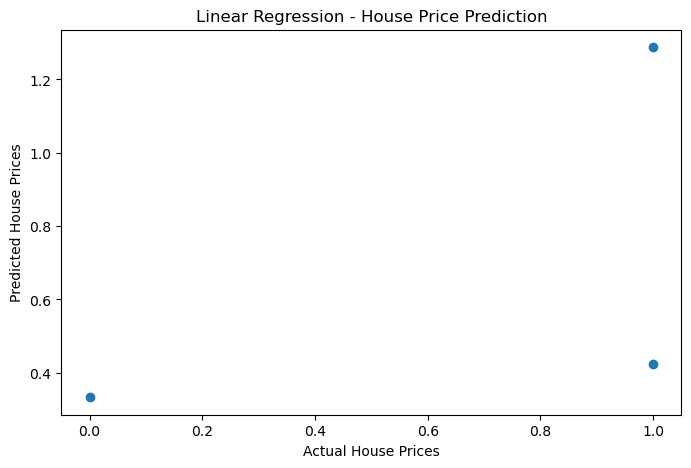

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.title("Linear Regression - House Price Prediction")

plt.show()

In [26]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.coef_
})

importance['Absolute Importance'] = abs(importance['Importance'])

print(importance.sort_values(
    by='Absolute Importance',
    ascending=False
))

       Feature  Importance  Absolute Importance
2     Humidity    0.606061             0.606061
3         Wind    0.454545             0.454545
0      Outlook   -0.196970             0.196970
1  Temperature    0.151515             0.151515


In [23]:
print("Conclusion:")
print("Decision Tree using Entropy was successfully implemented.")
print("The model classifies whether to play tennis or not.")

Conclusion:
Decision Tree using Entropy was successfully implemented.
The model classifies whether to play tennis or not.


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [12]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model Training Completed")

Model Training Completed


In [13]:
y_pred = model.predict(X_test)

In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 0.398989898989899
MSE: 0.17516069788797065
RMSE: 0.4185220399070647
R2 Score: 0.21177685950413216
